In [9]:
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import linregress
%matplotlib inline

BASE = '/content/drive/MyDrive/battery-cycling-quality-analytics'
DATA_PROCESSED = os.path.join(BASE, 'data', 'processed')
OUTPUTS = os.path.join(BASE, 'outputs', 'charts')
os.makedirs(OUTPUTS, exist_ok=True)

cap = pd.read_parquet(os.path.join(DATA_PROCESSED, 'nasa_pcoe_cycle_level.parquet'))
print(f"Loaded {len(cap):,} cycle-level rows")
print(f"Cells: {cap['cell_id'].unique().tolist()}")
print(cap.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded 636 cycle-level rows
Cells: ['B0005', 'B0006', 'B0007', 'B0018']
  cell_id  cycle_number  capacity_nasa_Ah  capacity_computed_Ah  abs_error_Ah  \
0   B0005             2          1.856487              1.862203      0.005715   
1   B0005             4          1.846327              1.852078      0.005751   
2   B0005             6          1.835349              1.841049      0.005700   
3   B0005             8          1.835263              1.840912      0.005649   
4   B0005            10          1.834646              1.840360      0.005714   

   pct_error  
0   0.307864  
1   0.311458  
2   0.310543  
3   0.307830  
4   0.311473  


In [10]:
def linear_model(x, a, b):
    """capacity = a - b * cycle"""
    return a - b * x

def exponential_model(x, a, b, c):
    """capacity = a * exp(-b * cycle) + c"""
    return a * np.exp(-b * x) + c

def r_squared(y_true, y_pred):
    """Coefficient of determination — how well does the model fit the data?"""
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

def fit_both_models(x, y):
    """
    Fit both linear and exponential to one cell's fade data.
    Return a dict with each model's parameters, predictions, and R².
    """
    results = {}

    # Linear fit
    try:
        popt_lin, _ = curve_fit(linear_model, x, y)
        y_pred_lin = linear_model(x, *popt_lin)
        results['linear'] = {
            'params': {'a': popt_lin[0], 'b': popt_lin[1]},
            'y_pred': y_pred_lin,
            'r2': r_squared(y, y_pred_lin),
            'model': linear_model,
            'popt': popt_lin,
        }
    except Exception as e:
        results['linear'] = {'error': str(e)}

    # Exponential fit — needs sensible initial guesses or it won't converge
    try:
        a0 = y.max() - y.min()                 # amplitude of decay
        b0 = 1.0 / (x.max() - x.min())         # rough decay rate
        c0 = y.min()                           # asymptote
        popt_exp, _ = curve_fit(exponential_model, x, y, p0=[a0, b0, c0], maxfev=5000)
        y_pred_exp = exponential_model(x, *popt_exp)
        results['exponential'] = {
            'params': {'a': popt_exp[0], 'b': popt_exp[1], 'c': popt_exp[2]},
            'y_pred': y_pred_exp,
            'r2': r_squared(y, y_pred_exp),
            'model': exponential_model,
            'popt': popt_exp,
        }
    except Exception as e:
        results['exponential'] = {'error': str(e)}

    return results

In [11]:
# Industry EOL threshold: 80% of starting capacity (per cell)
EOL_PCT = 0.80

summary_rows = []
fits = {}   # keep the fit objects for the plot in Cell 5

for cell_id in sorted(cap['cell_id'].unique()):
    d = cap[cap['cell_id'] == cell_id].sort_values('cycle_number')
    x = d['cycle_number'].values.astype(float)
    y = d['capacity_computed_Ah'].values

    cap_start = y.max()           # take the max as the "fresh" baseline
    eol_cap = EOL_PCT * cap_start

    results = fit_both_models(x, y)
    fits[cell_id] = {'x': x, 'y': y, 'results': results, 'cap_start': cap_start, 'eol_cap': eol_cap}

    # Pick the winner by R²
    valid = {k: v for k, v in results.items() if 'r2' in v}
    best_name = max(valid, key=lambda k: valid[k]['r2'])
    best = valid[best_name]

    # Predict cycle to EOL by inverting the model numerically
    # Simple approach: evaluate the fitted model over a wide cycle range, find first crossing
    cyc_grid = np.arange(1, 2000)
    cap_pred = best['model'](cyc_grid, *best['popt'])
    below = np.where(cap_pred <= eol_cap)[0]
    predicted_eol_cycle = int(cyc_grid[below[0]]) if len(below) > 0 else np.nan

    # Observed EOL (if the cell actually reached it in the data)
    observed_below = d[d['capacity_computed_Ah'] <= eol_cap]
    observed_eol_cycle = int(observed_below['cycle_number'].iloc[0]) if len(observed_below) > 0 else None

    summary_rows.append({
        'cell_id': cell_id,
        'n_cycles': len(d),
        'cap_start_Ah': round(cap_start, 3),
        'cap_end_Ah': round(y.min(), 3),
        'eol_threshold_Ah': round(eol_cap, 3),
        'best_model': best_name,
        'r2': round(best['r2'], 4),
        'observed_eol_cycle': observed_eol_cycle,
        'predicted_eol_cycle': predicted_eol_cycle,
    })

summary = pd.DataFrame(summary_rows)
print(summary.to_string(index=False))

cell_id  n_cycles  cap_start_Ah  cap_end_Ah  eol_threshold_Ah  best_model     r2  observed_eol_cycle  predicted_eol_cycle
  B0005       168         1.862       1.290             1.490 exponential 0.9806                 352                  373
  B0006       168         2.047       1.173             1.637 exponential 0.9826                 202                  209
  B0007       168         1.919       1.425             1.535 exponential 0.9849                 445                  442
  B0018       132         1.868       1.361             1.495 exponential 0.9580                 190                  202


Saved → /content/drive/MyDrive/battery-cycling-quality-analytics/outputs/charts/05_fade_rate_fits.png


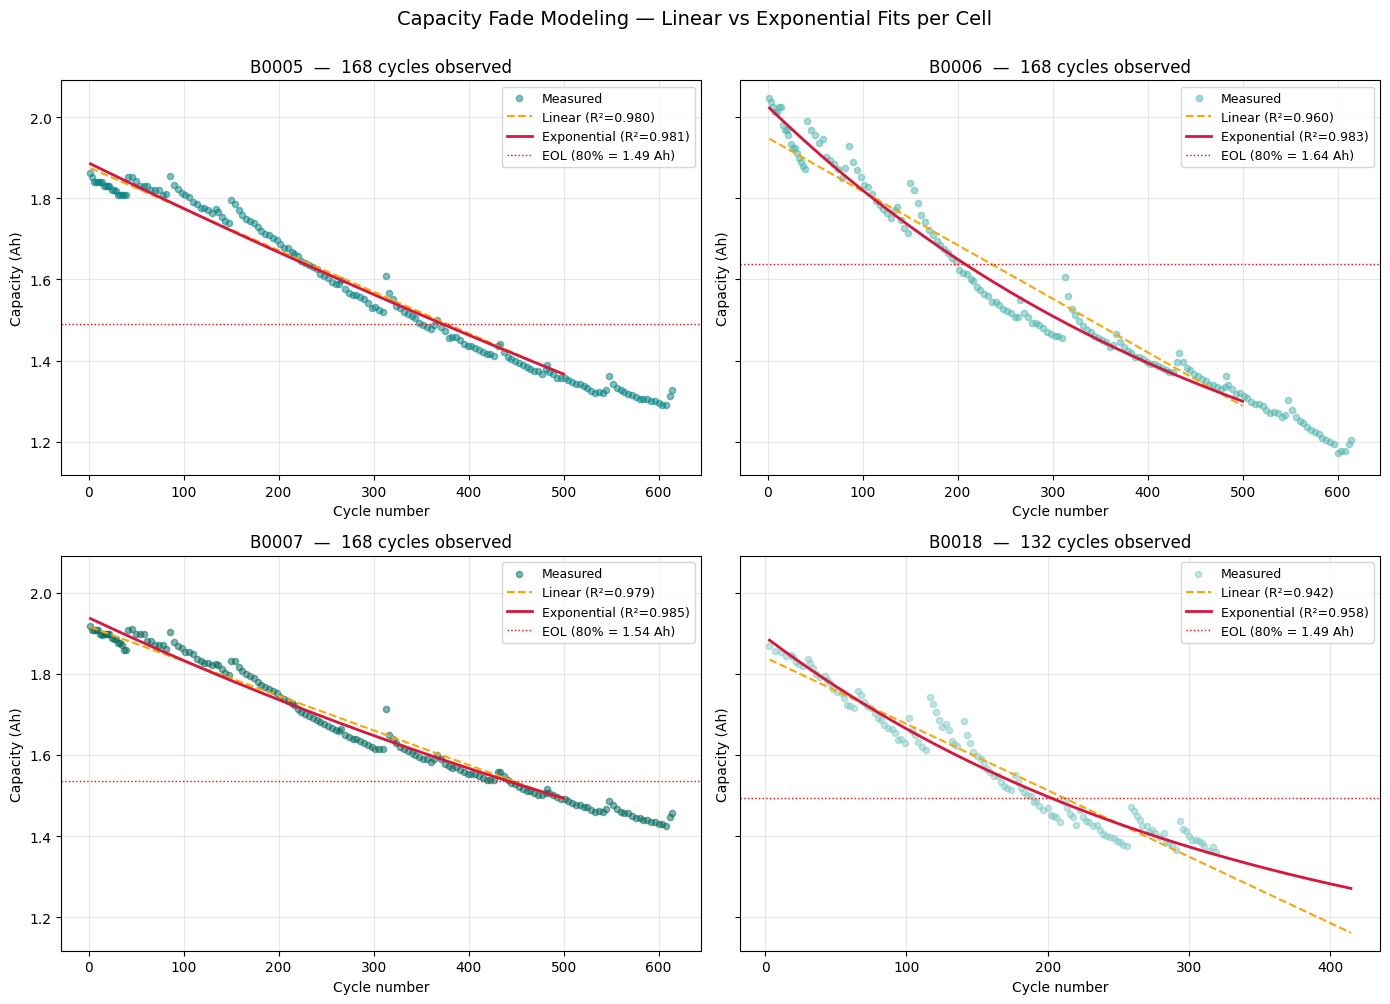

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharey=True)
axes = axes.flatten()

palette = {
    'B0005': '#008080',
    'B0006': '#4db6ac',
    'B0007': '#00695c',
    'B0018': '#80cbc4',
}

for ax, cell_id in zip(axes, sorted(fits.keys())):
    f = fits[cell_id]
    x, y = f['x'], f['y']
    results = f['results']
    cap_start = f['cap_start']
    eol_cap = f['eol_cap']

    # Raw data points
    ax.scatter(x, y, color=palette[cell_id], s=20, alpha=0.5, label='Measured')

    # Smooth curve for each fitted model
    x_smooth = np.linspace(x.min(), min(x.max() * 1.3, 500), 300)
    if 'r2' in results.get('linear', {}):
        ax.plot(x_smooth, linear_model(x_smooth, *results['linear']['popt']),
                color='orange', linewidth=1.5, linestyle='--',
                label=f"Linear (R²={results['linear']['r2']:.3f})")
    if 'r2' in results.get('exponential', {}):
        ax.plot(x_smooth, exponential_model(x_smooth, *results['exponential']['popt']),
                color='crimson', linewidth=2,
                label=f"Exponential (R²={results['exponential']['r2']:.3f})")

    # EOL line
    ax.axhline(eol_cap, color='red', linestyle=':', linewidth=1,
               label=f'EOL (80% = {eol_cap:.2f} Ah)')

    ax.set_title(f'{cell_id}  —  {len(x)} cycles observed', fontsize=12)
    ax.set_xlabel('Cycle number')
    ax.set_ylabel('Capacity (Ah)')
    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper right', fontsize=9)

plt.suptitle('Capacity Fade Modeling — Linear vs Exponential Fits per Cell',
             fontsize=14, y=1.00)
plt.tight_layout()

out_path = os.path.join(OUTPUTS, '05_fade_rate_fits.png')
fig.savefig(out_path, dpi=150, bbox_inches='tight')
print(f"Saved → {out_path}")

plt.show()

In [13]:
summary_path = os.path.join(OUTPUTS, '05_fade_summary.csv')
summary.to_csv(summary_path, index=False)
print(f"Saved summary → {summary_path}")
print()
print("Final summary:")
print(summary.to_string(index=False))

Saved summary → /content/drive/MyDrive/battery-cycling-quality-analytics/outputs/charts/05_fade_summary.csv

Final summary:
cell_id  n_cycles  cap_start_Ah  cap_end_Ah  eol_threshold_Ah  best_model     r2  observed_eol_cycle  predicted_eol_cycle
  B0005       168         1.862       1.290             1.490 exponential 0.9806                 352                  373
  B0006       168         2.047       1.173             1.637 exponential 0.9826                 202                  209
  B0007       168         1.919       1.425             1.535 exponential 0.9849                 445                  442
  B0018       132         1.868       1.361             1.495 exponential 0.9580                 190                  202
